<a href="https://colab.research.google.com/github/DanielLucero25/CSC349/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 349 HW6: Face Images and PCA

This notebook looks at face compression and compares four classification models. Run the cells from top to bottom. Saved outputs were checked in a local Python runtime. Run all cells in Google Colab and save the notebook back to GitHub for the required Colab execution. Training times depend on the computer.

## Task 1: Load and inspect the faces

I load the Olivetti Faces dataset directly from Scikit-Learn. X contains the pixel values and y contains the subject IDs. Each row has 4096 values because a face image is 64 by 64 pixels. The pixels are already between 0 and 1 so I keep that scale.

I print the number of images, subjects and features to check the data. I then show 20 faces in a 4 by 5 grid with their subject IDs. Taking every twentieth image shows different people rather than just the first two subjects.

Samples: 400
Subjects: 40
Features: 4096
Image shape: (64, 64)


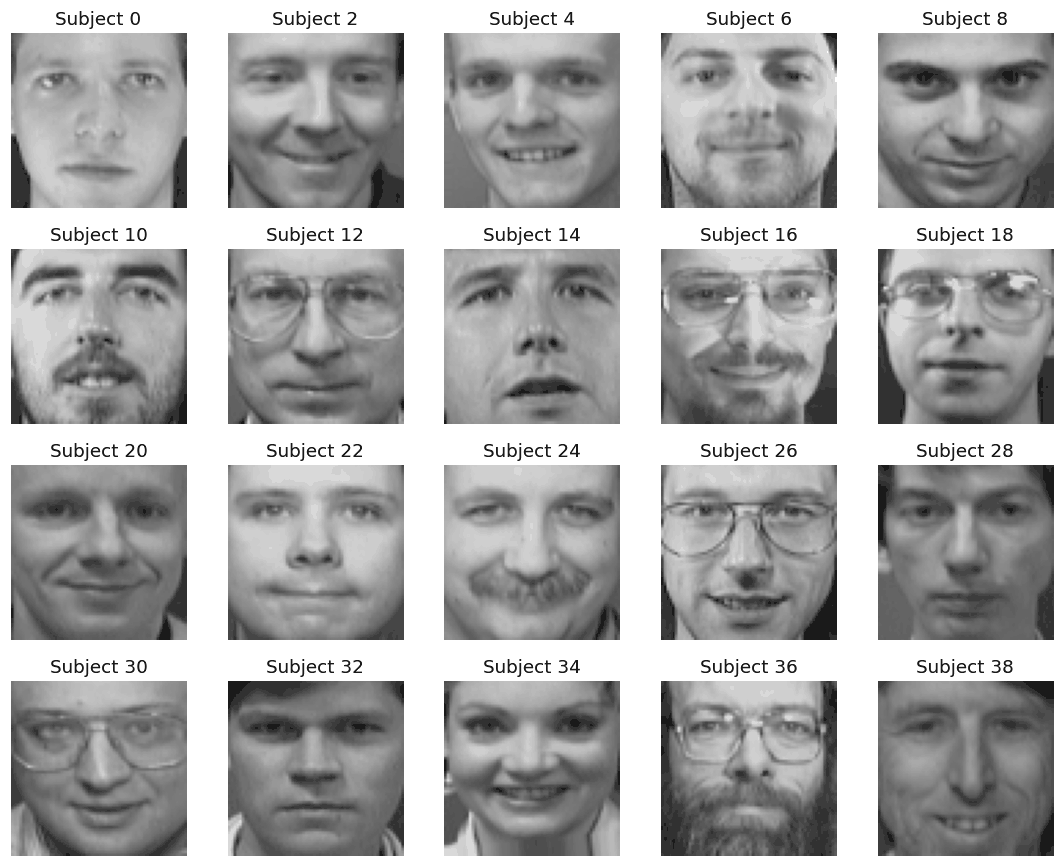

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter

from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, mean_squared_error, ConfusionMatrixDisplay

faces = fetch_olivetti_faces()
X = faces.data
y = faces.target

print('Samples:', X.shape[0])
print('Subjects:', len(np.unique(y)))
print('Features:', X.shape[1])
print('Image shape:', faces.images.shape[1:])

fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for ax, index in zip(axes.ravel(), range(0, 400, 20)):
    ax.imshow(faces.images[index], cmap='gray', vmin=0, vmax=1)
    ax.set_title('Subject ' + str(y[index]))
    ax.axis('off')
plt.tight_layout()
plt.show()

## Task 2: Explained variance

I fit a full PCA model to see how the image variation is spread across the components. The first graph shows the share explained by each component. The second adds these shares together. The steep part of the curve shows where adding components gives the largest improvement.

I find the first component count that reaches 90, 95 and 99 percent. This full-data PCA is only for exploring the dataset and making the reconstruction plots. I fit new PCA transformers using only training data when I compare classifiers later.

90% variance: 66 components
95% variance: 123 components
99% variance: 260 components


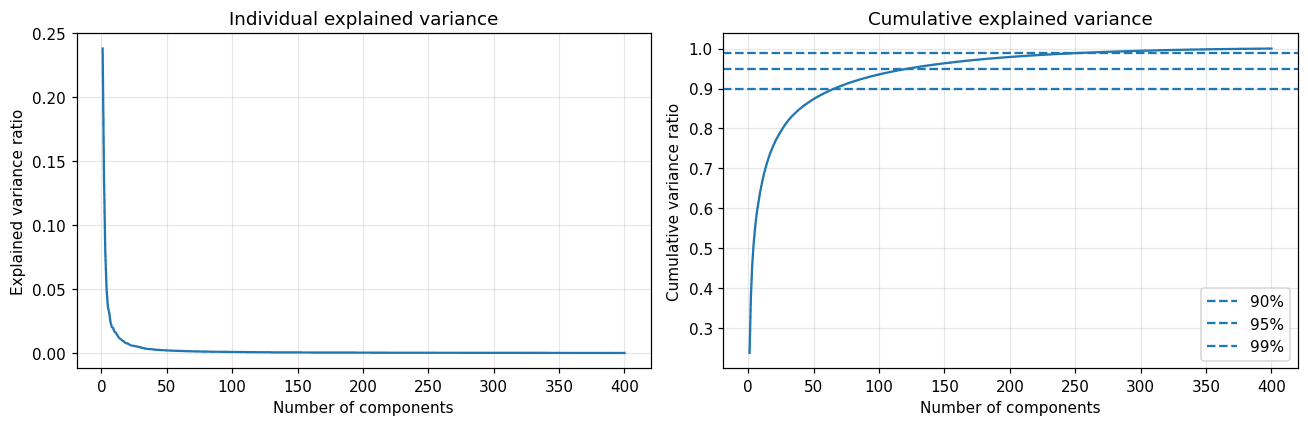

In [2]:
pca = PCA(svd_solver='full')
pca.fit(X)
variance = pca.explained_variance_ratio_
cumulative = np.cumsum(variance)
components = np.arange(1, len(variance) + 1)

for threshold in [0.90, 0.95, 0.99]:
    count = np.searchsorted(cumulative, threshold) + 1
    print(str(int(threshold * 100)) + '% variance:', count, 'components')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(components, variance)
axes[0].set_title('Individual explained variance')
axes[0].set_ylabel('Explained variance ratio')
axes[1].plot(components, cumulative)
for threshold in [0.90, 0.95, 0.99]:
    axes[1].axhline(threshold, linestyle='--', label=str(int(threshold * 100)) + '%')
axes[1].set_title('Cumulative explained variance')
axes[1].set_ylabel('Cumulative variance ratio')
axes[1].legend()
for ax in axes:
    ax.set_xlabel('Number of components')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3: Compress and reconstruct faces

I choose one image from each of five different subjects. For each component count I fit PCA, compress the five images with transform and bring them back to pixel space with inverse_transform. The grid puts each original next to its reconstructions so I can compare the same face at every level.

I calculate the mean squared error across these five images for each value of k. A smaller error means the reconstructed pixels are closer to the originals. All images use the same color scale so a change in the display settings does not hide the differences. These faces are part of the PCA fitting data so this checks reconstruction of known images.

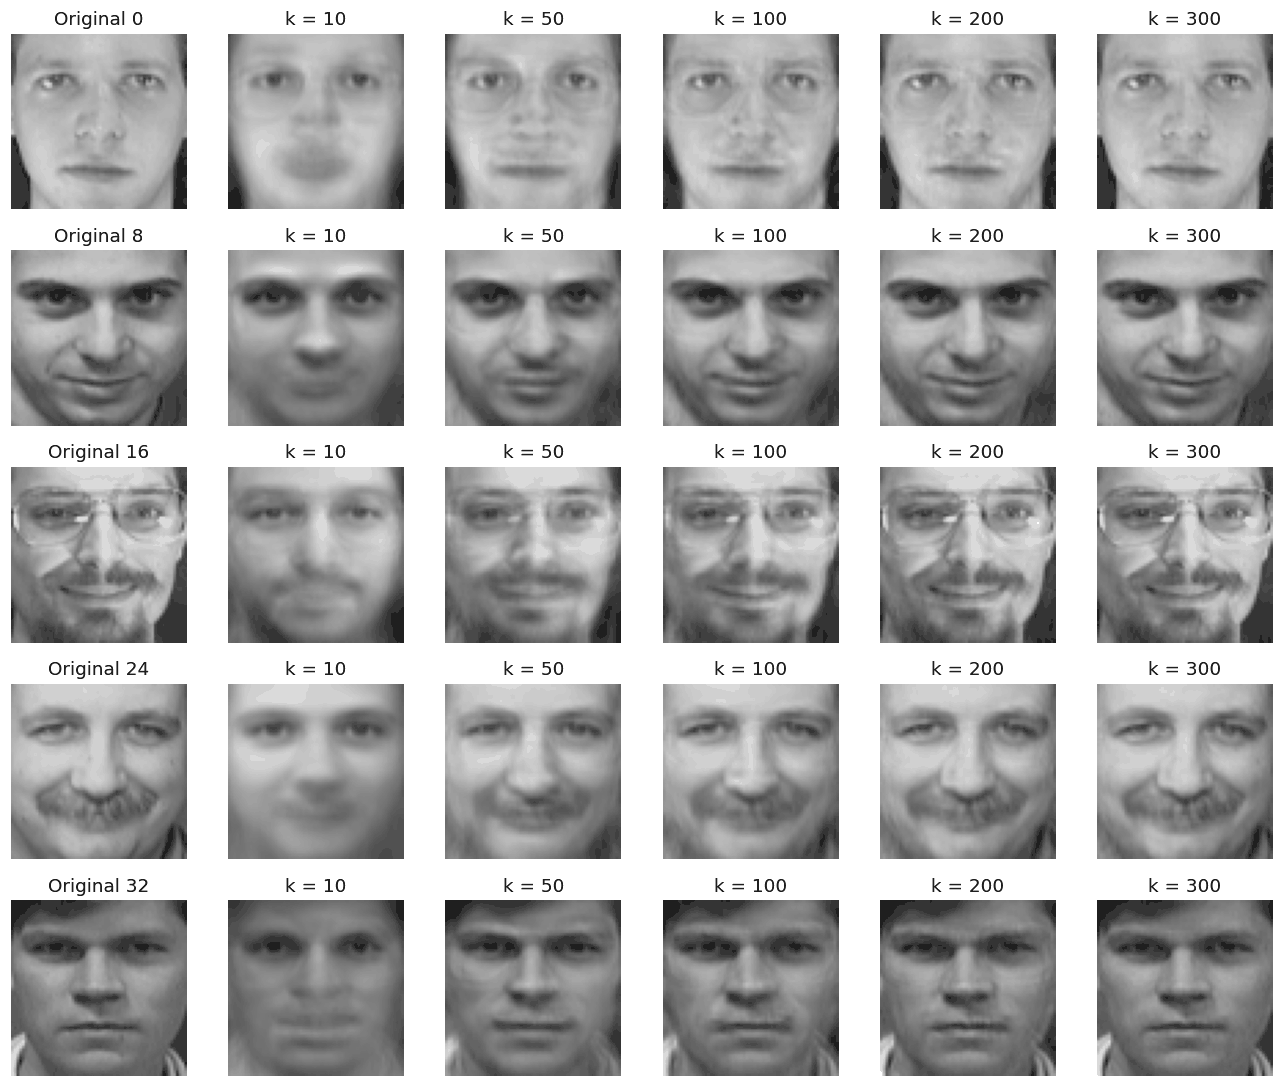

Components,MSE
10,0.005764
50,0.002117
100,0.001084
200,0.000398
300,0.000127


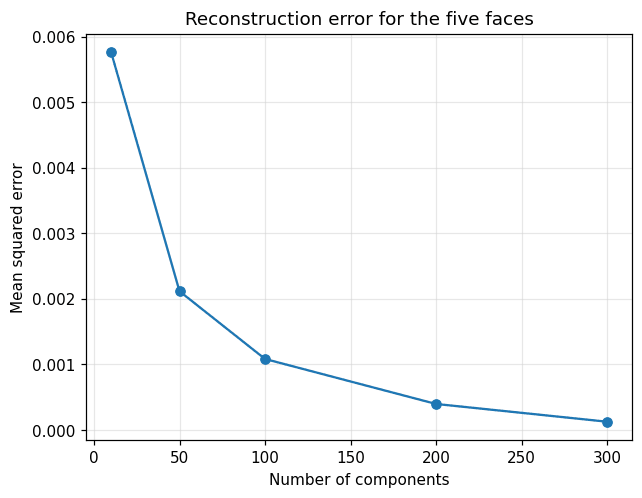

In [3]:
indices = [0, 80, 160, 240, 320]
selected_faces = X[indices]
k_values = [10, 50, 100, 200, 300]
errors = []

fig, axes = plt.subplots(5, 6, figsize=(12, 10))
for row, index in enumerate(indices):
    axes[row, 0].imshow(faces.images[index], cmap='gray', vmin=0, vmax=1)
    axes[row, 0].set_title('Original ' + str(y[index]))

for column, k in enumerate(k_values, start=1):
    compression = PCA(n_components=k, svd_solver='full')
    compression.fit(X)
    compressed = compression.transform(selected_faces)
    reconstructed = compression.inverse_transform(compressed)
    errors.append(mean_squared_error(selected_faces, reconstructed))
    for row in range(5):
        axes[row, column].imshow(reconstructed[row].reshape(64, 64),
                                cmap='gray', vmin=0, vmax=1)
        axes[row, column].set_title('k = ' + str(k))

for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

reconstruction_results = pd.DataFrame({'Components': k_values, 'MSE': errors})
display(reconstruction_results)
plt.plot(k_values, errors, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Mean squared error')
plt.title('Reconstruction error for the five faces')
plt.grid(alpha=0.3)
plt.show()

## Task 4: Show the eigenfaces

Each PCA component gives a pattern of pixel changes across the faces. I reshape the first 15 components into 64 by 64 images and show them in a 3 by 5 grid. These are patterns learned from all the images rather than pictures of individual people.

The title on each image gives that component's percentage of total variance. Bright and dark areas show pixels that change together or in opposite directions. The sign of a component can be reversed without changing what PCA learns.

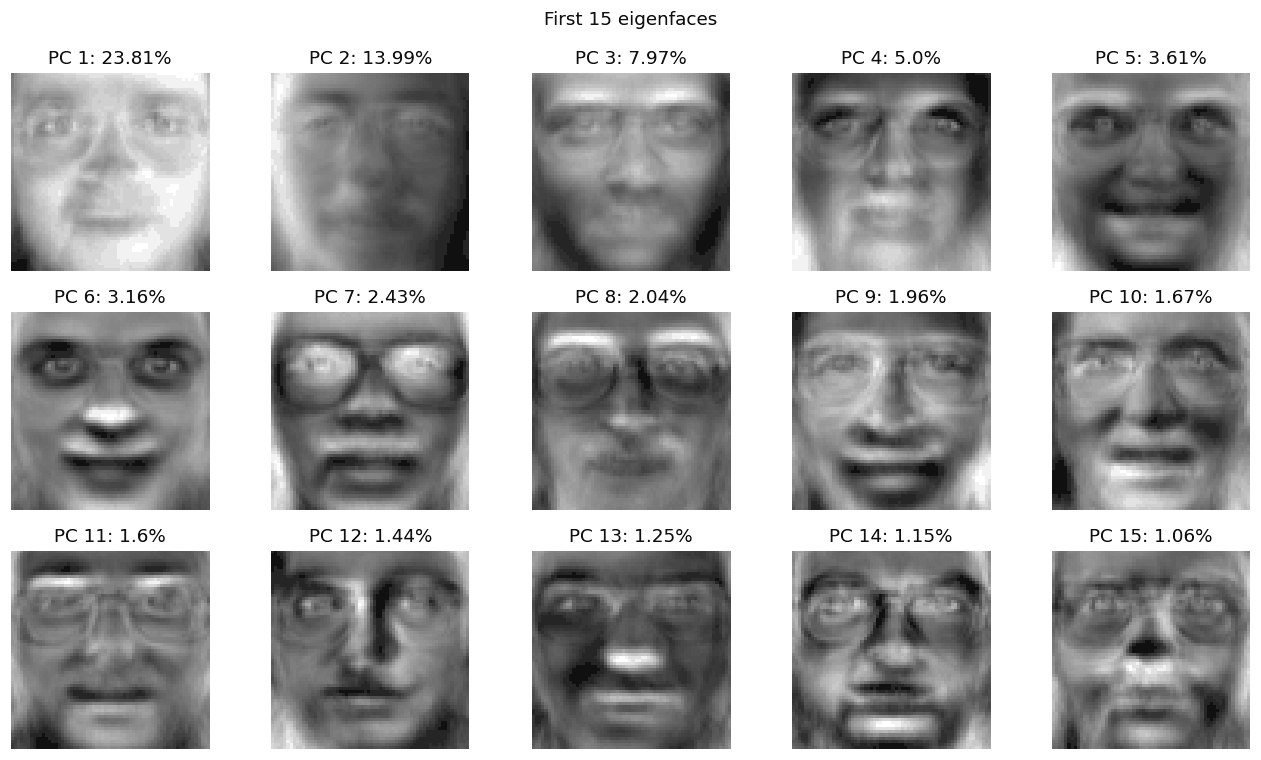

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(pca.components_[i].reshape(64, 64), cmap='gray')
    ax.set_title('PC ' + str(i + 1) + ': ' + str(round(variance[i] * 100, 2)) + '%')
    ax.axis('off')
plt.suptitle('First 15 eigenfaces')
plt.tight_layout()
plt.show()

## Task 5: Logistic regression with raw and PCA features

I split the images into 80 percent training and 20 percent testing. Stratify keeps images from all 40 subjects in both sets. I train logistic regression once on the raw pixels and once in a pipeline with PCA keeping 95 percent of training variance. The pipeline fits PCA only on the training images and uses that same transformation on the test images.

I measure the time for each complete fit. The PCA model time includes fitting PCA and logistic regression. Prediction time is not included. I print accuracy and seconds and show them on separate y axes because they use different units. I also print the training PCA component count since it can differ from Task 2.

Training images: 320
Test images: 80
Training PCA components: 111
Raw accuracy: 0.975 Training seconds: 3.8296
PCA accuracy: 0.9625 Training seconds: 0.2869


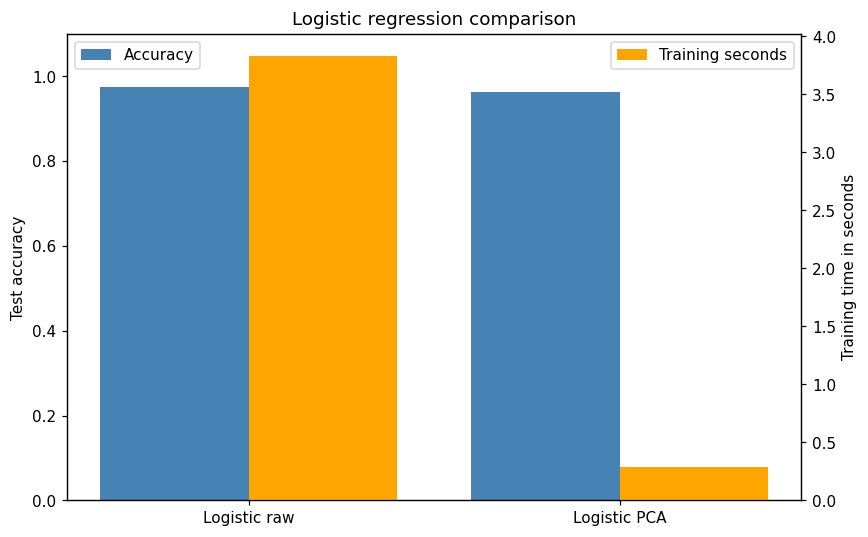

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

raw_model = LogisticRegression(max_iter=2000, random_state=42)
pca_model = Pipeline([
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', LogisticRegression(max_iter=2000, random_state=42))
])

start = perf_counter()
raw_model.fit(X_train, y_train)
raw_time = perf_counter() - start
raw_predictions = raw_model.predict(X_test)
raw_accuracy = accuracy_score(y_test, raw_predictions)

start = perf_counter()
pca_model.fit(X_train, y_train)
pca_time = perf_counter() - start
pca_predictions = pca_model.predict(X_test)
pca_accuracy = accuracy_score(y_test, pca_predictions)

print('Training images:', X_train.shape[0])
print('Test images:', X_test.shape[0])
print('Training PCA components:', pca_model.named_steps['pca'].n_components_)
print('Raw accuracy:', raw_accuracy, 'Training seconds:', round(raw_time, 4))
print('PCA accuracy:', pca_accuracy, 'Training seconds:', round(pca_time, 4))

positions = np.arange(2)
fig, ax1 = plt.subplots(figsize=(8, 5))
ax2 = ax1.twinx()
ax1.bar(positions - 0.2, [raw_accuracy, pca_accuracy], width=0.4,
        color='steelblue', label='Accuracy')
ax2.bar(positions + 0.2, [raw_time, pca_time], width=0.4,
        color='orange', label='Training seconds')
ax1.set_xticks(positions, ['Logistic raw', 'Logistic PCA'])
ax1.set_ylim(0, 1.1)
ax1.set_ylabel('Test accuracy')
ax2.set_ylabel('Training time in seconds')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.title('Logistic regression comparison')
plt.tight_layout()
plt.show()

## Task 6: RBF kernel SVM

I train an RBF SVC using the same training and test split. Its pipeline fits a new PCA transformer to the training data and keeps 95 percent of variance. The RBF kernel can make curved boundaries between subjects instead of only using straight boundaries.

I record the full fit time and test accuracy in the same way as Task 5. I compare its confusion matrix with logistic regression on PCA features. Both matrices use subject IDs from 0 to 39. Correct predictions appear on the diagonal and other squares show which subjects were confused.

RBF SVC accuracy: 0.9375
Training seconds: 0.2296


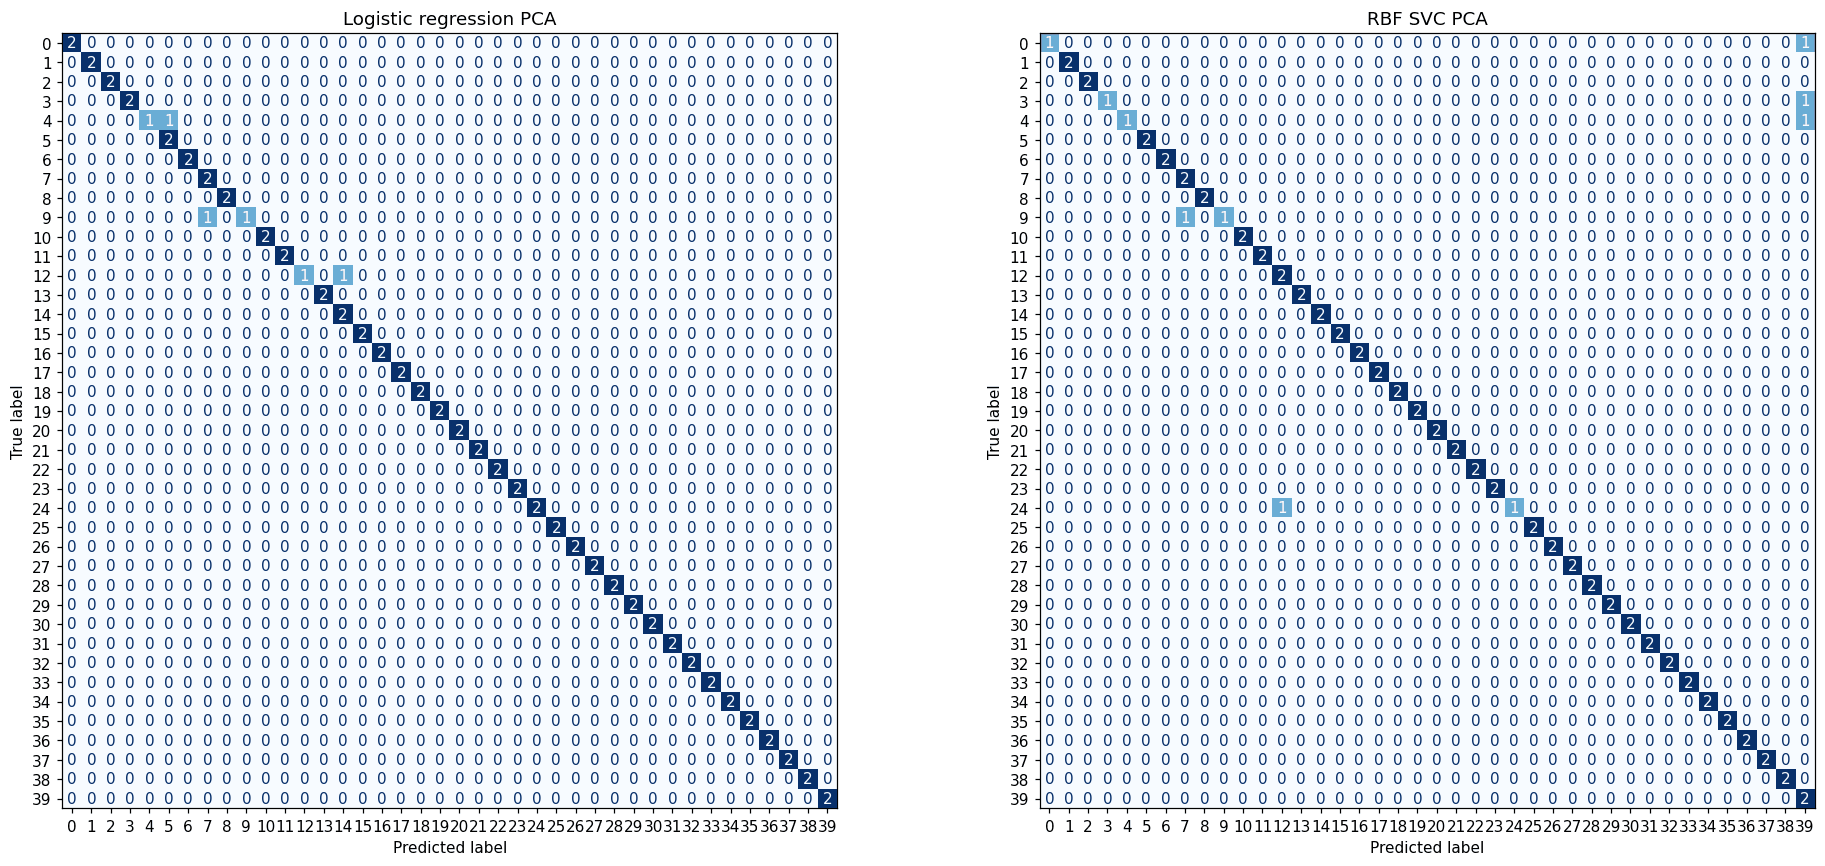

In [6]:
svm_model = Pipeline([
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', SVC(kernel='rbf', random_state=42))
])
start = perf_counter()
svm_model.fit(X_train, y_train)
svm_time = perf_counter() - start
svm_predictions = svm_model.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_predictions)
print('RBF SVC accuracy:', svm_accuracy)
print('Training seconds:', round(svm_time, 4))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
ConfusionMatrixDisplay.from_predictions(y_test, pca_predictions, ax=axes[0],
                                       colorbar=False, cmap='Blues')
ConfusionMatrixDisplay.from_predictions(y_test, svm_predictions, ax=axes[1],
                                       colorbar=False, cmap='Blues')
axes[0].set_title('Logistic regression PCA')
axes[1].set_title('RBF SVC PCA')
plt.tight_layout()
plt.show()

## Task 7: Soft voting ensemble

I combine a degree 2 polynomial SVM, an RBF SVM and a random forest with 100 trees. Soft voting averages their class probabilities. Both SVMs need probability=True so they can take part in this vote. All three models get the same PCA features from a transformer fitted only on training images.

I measure the time for the whole pipeline fit including PCA and probability estimation. I print accuracy and compare it with the single PCA models. Combining models does not guarantee a better result. If they make similar mistakes or one gives weak probabilities the average can be less useful.

Soft voting accuracy: 0.95
Training seconds: 0.6619


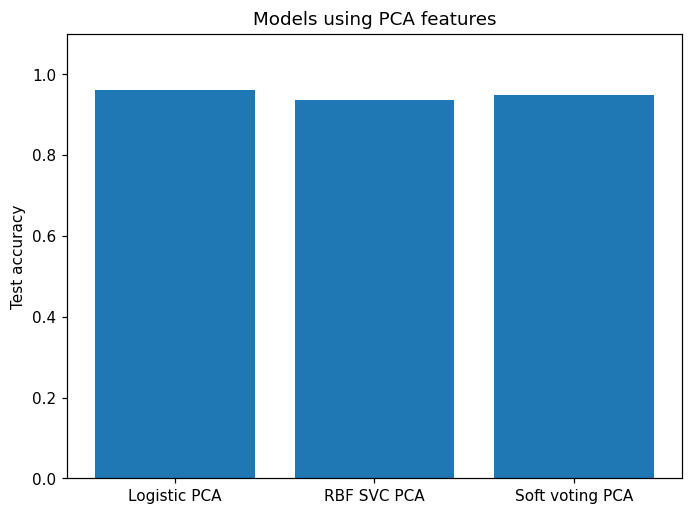

In [7]:
voting = VotingClassifier(estimators=[
    ('poly', SVC(kernel='poly', degree=2, probability=True, random_state=42)),
    ('rbf', SVC(kernel='rbf', probability=True, random_state=42)),
    ('forest', RandomForestClassifier(n_estimators=100, random_state=42))
], voting='soft')

ensemble_model = Pipeline([
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', voting)
])
start = perf_counter()
ensemble_model.fit(X_train, y_train)
ensemble_time = perf_counter() - start
ensemble_predictions = ensemble_model.predict(X_test)
ensemble_accuracy = accuracy_score(y_test, ensemble_predictions)
print('Soft voting accuracy:', ensemble_accuracy)
print('Training seconds:', round(ensemble_time, 4))

plt.bar(['Logistic PCA', 'RBF SVC PCA', 'Soft voting PCA'],
        [pca_accuracy, svm_accuracy, ensemble_accuracy])
plt.ylabel('Test accuracy')
plt.ylim(0, 1.1)
plt.title('Models using PCA features')
plt.tight_layout()
plt.show()

## Task 8: Compare all four models

I put the four test accuracies and training times into one table and one graph. Each model used the same split so the comparison uses the same 80 test images. The blue bars use the accuracy axis and the orange bars use the seconds axis. The numbers above the bars make the values easier to read.

The timing includes each model's full fit. This includes PCA for the three PCA pipelines and the extra SVM probability calculations for soft voting. These are single timing measurements so small differences may change on another run. A high score on this small dataset also does not show that the model will work equally well on other face images.

Model,Accuracy,Training seconds
Logistic raw,0.9750,3.829617
Logistic PCA,0.9625,0.286913
RBF SVC PCA,0.9375,0.229588
Soft voting PCA,0.9500,0.661895


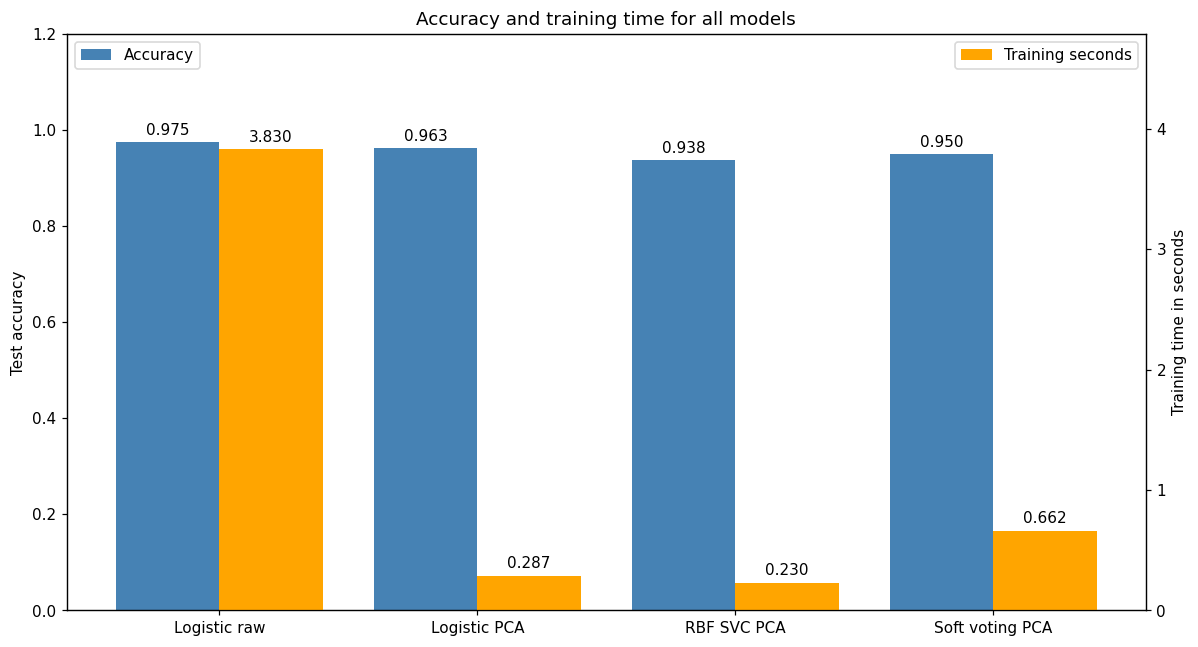

In [8]:
results = pd.DataFrame({
    'Model': ['Logistic raw', 'Logistic PCA', 'RBF SVC PCA', 'Soft voting PCA'],
    'Accuracy': [raw_accuracy, pca_accuracy, svm_accuracy, ensemble_accuracy],
    'Training seconds': [raw_time, pca_time, svm_time, ensemble_time]
})
display(results)

positions = np.arange(4)
fig, ax1 = plt.subplots(figsize=(11, 6))
ax2 = ax1.twinx()
accuracy_bars = ax1.bar(positions - 0.2, results['Accuracy'], width=0.4,
                        color='steelblue', label='Accuracy')
time_bars = ax2.bar(positions + 0.2, results['Training seconds'], width=0.4,
                   color='orange', label='Training seconds')
ax1.bar_label(accuracy_bars, fmt='%.3f', padding=3)
ax2.bar_label(time_bars, fmt='%.3f', padding=3)
ax1.set_xticks(positions, results['Model'])
ax1.set_ylim(0, 1.2)
ax2.set_ylim(0, results['Training seconds'].max() * 1.25)
ax1.set_ylabel('Test accuracy')
ax2.set_ylabel('Training time in seconds')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')
plt.title('Accuracy and training time for all models')
plt.tight_layout()
plt.show()